<a href="https://colab.research.google.com/github/incrisvel/adaptaste/blob/main/classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
%pip -q install pandas scikit-learn plotly

In [5]:
import pandas as pd
import json

# Abre arquivo de reviews
with open('reviews_preprocessed.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

df = pd.DataFrame(data)

## Preparação dos dados

In [13]:
RATING_COLUMN = "rating"

classification_df = df.copy()

classification_df[RATING_COLUMN] = pd.to_numeric(
    classification_df[RATING_COLUMN],
    errors="coerce"
)

# Mantém notas extremas e remove notas intermediárias.
classification_df = classification_df[
    classification_df[RATING_COLUMN].isin([1, 2, 4, 5])
].copy()

classification_df["label"] = (
    classification_df[RATING_COLUMN] >= 4
).astype(int)

print(classification_df["label"].value_counts())

if classification_df["label"].nunique() < 2:
    raise ValueError(
        "A base precisa conter exemplos das duas classes."
    )

label
1    2116
0      96
Name: count, dtype: int64


## Classificação: Unigramas x Unigramas e Bigramas Pré-processados

A fim de comparar o desempenho de classificação do modelo utilizando unigramas ou bigramas, cria-se uma nova entrada combinando os tokens de `description_lemmatized` (unigramas) e `description_bigrams` (bigramas representados como tokens únicos) para treinar o classificador.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

TEXT_COLUMN = "description_lemmatized"

# Converte as listas de tokens em texto corrido, permitindo usar o gerador de n-gramas nativo do TfidfVectorizer
X_text_joined = classification_df[TEXT_COLUMN].apply(lambda tokens: " ".join(tokens) if isinstance(tokens, list) else "")
y = classification_df["label"]

# Divisão estável para os dois experimentos
X_train_j, X_test_j, y_train_j, y_test_j = train_test_split(
    X_text_joined,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Experimento 1: Apenas Unigramas
pipeline_unigrama = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 1),
            sublinear_tf=True
        )
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Experimento 2: Unigramas + Bigramas
pipeline_bigrama = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            sublinear_tf=True
        )
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Treinando ambos os pipelines
pipeline_unigrama.fit(X_train_j, y_train_j)
y_pred_uni = pipeline_unigrama.predict(X_test_j)

pipeline_bigrama.fit(X_train_j, y_train_j)
y_pred_combined = pipeline_bigrama.predict(X_test_j)

# Alinhando variáveis de teste para a próxima célula rodar sem erros
y_test_c = y_test_j

### Desempenho: Unigramas

RESULTADOS COM APENAS UNIGRAMAS
              precision    recall  f1-score   support

    Negativa       0.55      0.63      0.59        19
    Positiva       0.98      0.98      0.98       424

    accuracy                           0.96       443
   macro avg       0.76      0.80      0.78       443
weighted avg       0.96      0.96      0.96       443



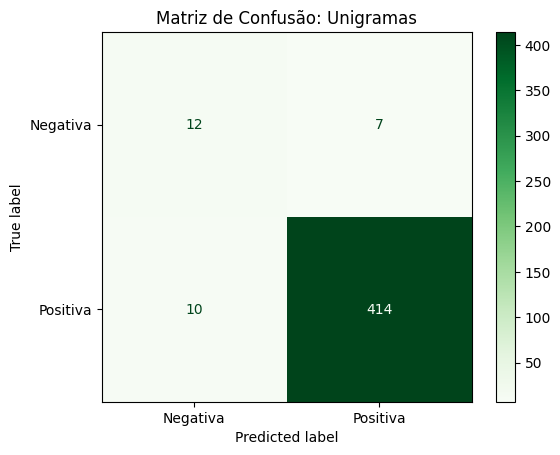

In [30]:
# Avaliação do desempenho: Unigramas
print("RESULTADOS COM APENAS UNIGRAMAS")
print(classification_report(y_test_c, y_pred_uni, target_names=["Negativa", "Positiva"], zero_division=0))

# Exibindo a matriz de confusão: Unigramas
ConfusionMatrixDisplay.from_predictions(
    y_test_c,
    y_pred_uni,
    labels=[0, 1],
    display_labels=["Negativa", "Positiva"],
    cmap="Greens"
)
plt.title("Matriz de Confusão: Unigramas")
plt.show()

### Desempenho: Unigramas + Bigramas

RESULTADOS COM UNIGRAMAS E BIGRAMAS PRÉ-PROCESSADOS
              precision    recall  f1-score   support

    Negativa       0.67      0.53      0.59        19
    Positiva       0.98      0.99      0.98       424

    accuracy                           0.97       443
   macro avg       0.82      0.76      0.79       443
weighted avg       0.97      0.97      0.97       443



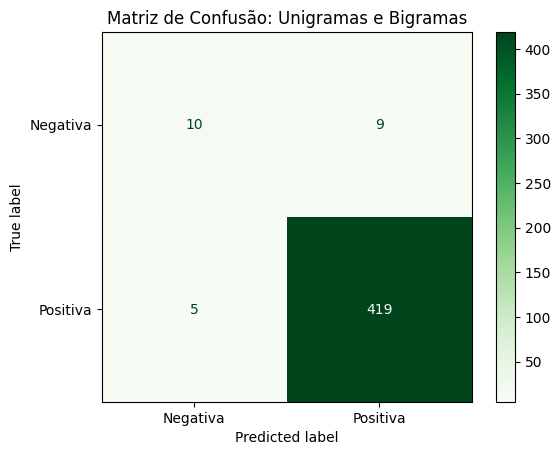

In [31]:
# Avaliação do desempenho: Unigramas + Bigramas
print("RESULTADOS COM UNIGRAMAS E BIGRAMAS PRÉ-PROCESSADOS")
print(classification_report(y_test_c, y_pred_combined, target_names=["Negativa", "Positiva"], zero_division=0))

# Exibindo a matriz de confusão: Unigramas + Bigramas
ConfusionMatrixDisplay.from_predictions(
    y_test_c,
    y_pred_combined,
    labels=[0, 1],
    display_labels=["Negativa", "Positiva"],
    cmap="Greens"
)
plt.title("Matriz de Confusão: Unigramas e Bigramas")
plt.show()